Heart Failure Prediction Using Machine Learning
Objective: This notebook explores the Heart Failure Clinical Records dataset and develops models to predict DEATH_EVENT (0 = no death recorded during follow-up, 1 = death recorded during follow-up). The work includes a data audit, preprocessing, a simple baseline model, cross-validation and an initial evaluation of three machine learning models.

In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

The CSV file is loaded into a pandas DataFrame. The first few records, dataset dimensions and variable types are checked to understand the data. Missing values and duplicate rows are counted, the distribution of the target variable (DEATH_EVENT) is examined, and summary statistics are calculated for the numerical variables.

In [ ]:

import pandas as pd

# Load dataset
df = pd.read_csv('heart_failure_clinical_records_dataset.csv')

# Check dataset
print("Dataset shape:", df.shape)
display(df.head())
df.info()

# Check missing values and duplicates
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

# Check target variable distribution
print("\nDeath event counts:\n", df['DEATH_EVENT'].value_counts())
print("\nDeath event percentages:\n",
      df['DEATH_EVENT'].value_counts(normalize=True) * 100)

# Summary statistics
display(df.describe())


Explore distributions and potential outliers
Continuous and binary variables are identified. Boxplots are created for the six continuous variables to look for unusually high or low values. Potential outliers are flagged using the 1.5 × interquartile range (IQR) rule, these are not automatically removed, because extreme clinical measurements may be meaningful. A bar chart is also used to show the number of patients in each target class.

The IQR check flags possible outliers in creatinine phosphokinase, platelets, serum creatinine and some other variables.

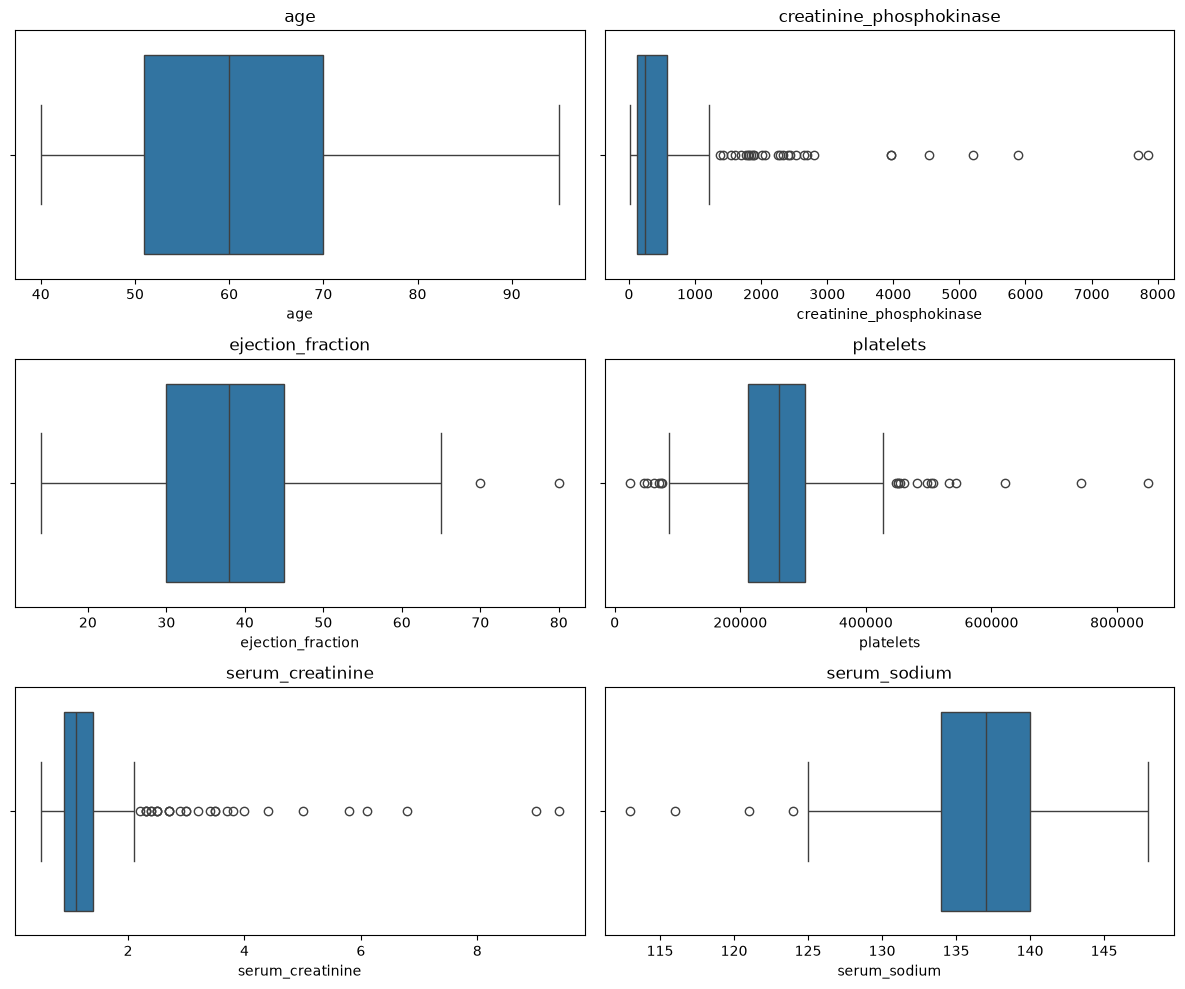

Potential outliers (IQR flags, NOT records removed):
age                          0
creatinine_phosphokinase    29
ejection_fraction            2
platelets                   21
serum_creatinine            29
serum_sodium                 4
dtype: int64


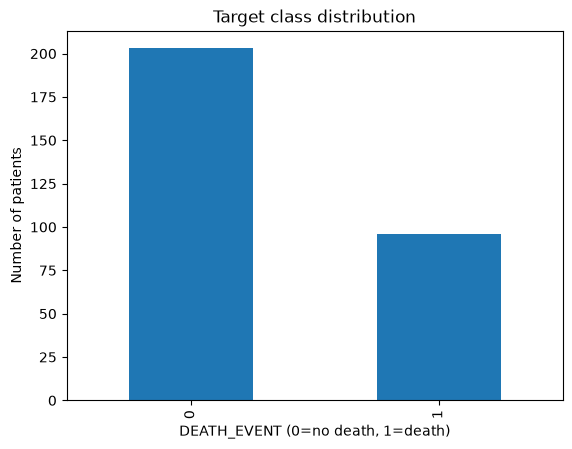

In [3]:
continuous_cols = [
    'age', 'creatinine_phosphokinase', 'ejection_fraction',
    'platelets', 'serum_creatinine', 'serum_sodium'
]
binary_cols = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking']

fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for ax, col in zip(axes.flat, continuous_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

q1 = df[continuous_cols].quantile(0.25)
q3 = df[continuous_cols].quantile(0.75)
iqr = q3 - q1
outlier_flags = (
    df[continuous_cols].lt(q1 - 1.5 * iqr) |
    df[continuous_cols].gt(q3 + 1.5 * iqr)
)
print('Potential outliers (IQR flags, NOT records removed):')
print(outlier_flags.sum())

df['DEATH_EVENT'].value_counts().reindex([0, 1], fill_value=0).plot(kind='bar')
plt.title('Target class distribution')
plt.xlabel('DEATH_EVENT (0=no death, 1=death)')
plt.ylabel('Number of patients')
plt.show()

The predictor matrix X contains the six continuous and five binary variables, while y contains DEATH_EVENT. The dataset is split into 80% training, 10% validation and 10% testing using two calls to train_test_split.

Stratification keeps the death-event proportion approximately similar across splits. The training set is used to fit models, the validation set to inspect preliminary performance, and the test set is held back for a final assessment. The time column is not included because it measures follow-up time, which may not be known when making a prediction at the start of follow-up.

In [ ]:
feature_cols = continuous_cols + binary_cols
# Select predictors and target
X = df.drop(columns=['DEATH_EVENT'])
y = df['DEATH_EVENT']

# Split into training (80%) and temporary (20%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Split temporary data into validation (10%) and test (10%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# Check the split
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))